# 06 — Making the model survive a bigger defect
Notebook 05 showed 56.5 % on 0.021" faults. Two questions: *which features break*, and *how do we choose features without tuning on the test set?*

In [1]:
import sys; sys.path.insert(0, '../src')
import numpy as np, matplotlib.pyplot as plt
import bearing as b
plt.rcParams['figure.dpi'] = 110

In [2]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
sev = {'0.007': {k: v for k, v in b.FILES.items() if v[1] == 0 and v[0] != 'normal'},
       '0.014': b.FILES_014, '0.021': b.FILES_021}
data = {s: b.dataset([0], files=f) for s, f in sev.items()}
Xn, yn, _, pn = b.dataset([0], files={97: ('normal', 0)})  # normal: time split 70/30
groups = {
    'all 17': b.FEATURE_NAMES,
    'time domain': ['rms', 'peak', 'crest', 'kurtosis', 'skewness', 'std'],
    'FFT bands': [f'band{i}' for i in range(8)],
    'envelope (physics)': b.ENV_FEATURES,
}
cols = lambda names: [b.FEATURE_NAMES.index(n) for n in names]

## Leave-one-severity-out
For each defect size: train on the other two (+ first 70 % of normal), test on the held-out size (+ last 30 % of normal). The feature set is chosen by the **mean** over the three folds, never by one test result.

In [3]:
rows = {}
for g, names in groups.items():
    c = cols(names); accs = []
    for held in sev:
        tr = [data[s] for s in sev if s != held]
        Xtr = np.vstack([d[0] for d in tr] + [Xn[pn < .7]]); ytr = np.concatenate([d[1] for d in tr] + [yn[pn < .7]])
        Xte = np.vstack([data[held][0], Xn[pn >= .7]]); yte = np.r_[data[held][1], yn[pn >= .7]]
        clf = RandomForestClassifier(n_estimators=200, random_state=0).fit(Xtr[:, c], ytr)
        accs.append(accuracy_score(yte, clf.predict(Xte[:, c])))
    rows[g] = accs
    print(f'{g:20s}', '  '.join(f'{s}: {a:.3f}' for s, a in zip(sev, accs)), f'  mean {np.mean(accs):.3f}')

all 17               0.007: 0.995  0.014: 0.362  0.021: 0.368   mean 0.575


time domain          0.007: 0.362  0.014: 0.319  0.021: 0.676   mean 0.452


FFT bands            0.007: 0.551  0.014: 0.341  0.021: 0.059   mean 0.317


envelope (physics)   0.007: 0.919  0.014: 0.373  0.021: 0.973   mean 0.755


all 17               0.007 -> 0.021 accuracy = 0.593
envelope (physics)   0.007 -> 0.021 accuracy = 0.977


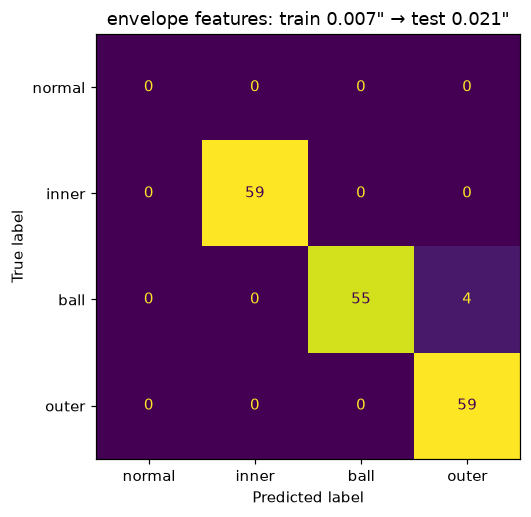

In [4]:
# the original question again: train on 0.007" (all 0 HP), test on 0.021"
Xtr, ytr, _, _ = b.dataset(loads=[0])
X21, y21, _, _ = data['0.021']
for g in ['all 17', 'envelope (physics)']:
    c = cols(groups[g])
    clf = RandomForestClassifier(n_estimators=200, random_state=0).fit(Xtr[:, c], ytr)
    print(f'{g:20s} 0.007 -> 0.021 accuracy = {accuracy_score(y21, clf.predict(X21[:, c])):.3f}')
ConfusionMatrixDisplay.from_estimator(clf, X21[:, c], y21, labels=b.CLASSES, colorbar=False)
plt.title('envelope features: train 0.007" → test 0.021"'); plt.tight_layout(); plt.savefig('../images/01-env-features-021-cm.png')

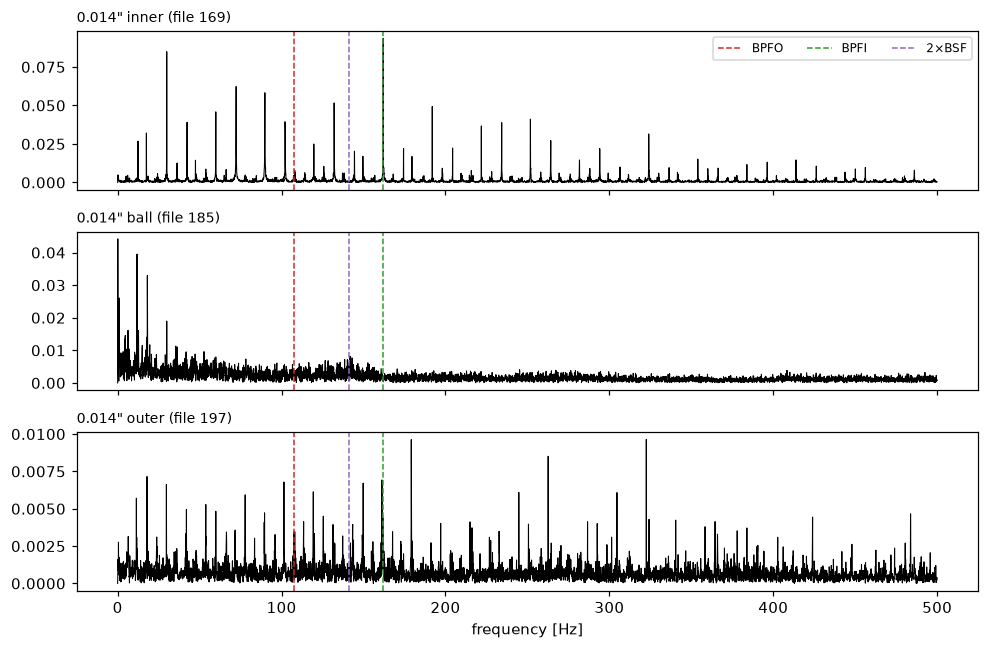

In [5]:
# why is 0.014" hard for every model? look at its envelope spectra
fig, axes = plt.subplots(3, 1, figsize=(9, 6), sharex=True)
for ax, (num, (cond, _)) in zip(axes, b.FILES_014.items()):
    x, rpm = b.load(num); f, a = b.envelope_spectrum(x); ff = b.fault_freqs(rpm); m = f < 500
    ax.plot(f[m], a[m], lw=0.7, color='k')
    for t, col, lab in [(ff['BPFO'], 'tab:red', 'BPFO'), (ff['BPFI'], 'tab:green', 'BPFI'), (2 * ff['BSF'], 'tab:purple', '2×BSF')]:
        ax.axvline(t, color=col, ls='--', lw=1, label=lab)
    ax.set_title(f'0.014" {cond} (file {num})', fontsize=9, loc='left')
axes[0].legend(fontsize=8, ncol=3); axes[-1].set_xlabel('frequency [Hz]')
fig.tight_layout(); fig.savefig('../images/01-envelope-014.png')

The 0.014" outer race recording (197) has **no dominant peak at BPFO** — its largest envelope peaks (~180 and ~322 Hz) match no fault frequency. The ball recording shows no clear 2×BSF peak either. Smith & Randall's CWRU benchmark (2015) also classes several of these recordings as not clearly diagnosable. No feature set can learn a fault signature that isn't in the signal, so 0.014" stays low and is reported as a data limitation, not hidden.